# L08 – 3D reconstruction with structured light

Computational Imaging, 2026 — Weerathep Rattanajaratkul

Section and step numbers (e.g. `B.2.3`) are those of the handout.

### Important implementation details

1. Functions marked **OWN** must be written by you with NumPy array operations only (no ready-made implementation from OpenCV, scikit-image, SciPy or similar). Everything that is not marked OWN may use any library: loading and saving files, conversion of data types and color, resizing, the fast Fourier transform, plotting, and whatever a step allows explicitly.
1. RGB images are NumPy arrays (`ndarray`) of shape (height, width, 3) with float values in [0, 1]; grayscale images have shape (height, width).
1. You get points for a step only if its result (image, plot, number or written answer) is rendered in the submitted notebook. The comment `Expected output` of every cell says what must be visible.
1. Keep the names and the first arguments of the given functions; you may add arguments with default values and any number of helper functions.
1. Please respect the folder structure (you may add subfolders):
    - `setup-ref` — data of the reference setup (provided): `calibration-data`, `reconstruction-dataset`, `panel_upper_points.npy`, `panel_lower_points.npy`
    - `setup-act` — data of your setup, same structure, plus `structured-light-patterns`, `calibration-dataset` (two photos per pose), `plane-dataset`
    - `setup-***/calibration-data` — eight .npy files: intrinsic matrix, distortion vector, rotation matrix, translation vector of camera and projector (world to device)
1. You may use any library; only the functions marked OWN are restricted.
1. Use an interactive 3D plot (`%matplotlib notebook` or `widget`) while you work, and a static view in the submitted notebook.

### General imports

In [1]:
%matplotlib inline
import math
import os
from glob import glob

import cv2 as cv
import matplotlib.pyplot as plt  # You may use a different plotting engine
import numpy as np
import itertools

### Auxiliary functions (ready to use)

In [2]:
def display_images(cont, cols=2, cmap='gray', vmin=None, vmax=None):
    """Displays images from a dictionary {caption: image} in a grid

    Args:
        cont: dictionary with images (height x width x 3, or height x width)
        cols: number of columns of the grid
        cmap, vmin, vmax: passed to imshow for single-channel images
    """

    # This function is ready to use. DO NOT CHANGE IT unless it is really necessary.

    rows = math.ceil(len(cont) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows), squeeze=False, constrained_layout=True)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, (caption, image) in zip(axes.ravel(), cont.items()):
        ax.set_title(caption)
        if image.ndim == 3:
            ax.imshow(np.clip(image, 0, 1))
        else:
            ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.show()

In [3]:
def load_images(names, display=True, max_side=1500):
    """Loads image files into a dictionary {caption: RGB image as float array in [0, 1]}

    Args:
        names: list of image files to load (caption = file name without extension)
        display: flag that defines if images should be displayed
        max_side: images with a longer side are downsized to this size (None: keep full resolution)

    Returns:
        Dictionary with loaded images
    """

    # This function is ready to use. DO NOT CHANGE IT unless it is really necessary.

    images = {}
    for name in sorted(names):
        image = cv.imread(name, cv.IMREAD_COLOR)
        if image is None:
            print('Cannot read', name)
            continue
        image = cv.cvtColor(image, cv.COLOR_BGR2RGB).astype(np.float64) / 255.0
        if max_side is not None and max(image.shape[:2]) > max_side:
            scale = max_side / max(image.shape[:2])
            image = cv.resize(image, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)
        images[os.path.splitext(os.path.basename(name))[0]] = image
    if not images:
        print('No images loaded')
    elif display:
        display_images(images)
    return images

In [4]:
def to_gray(image):
    """Converts an RGB image (float, linear weights of Rec. 709) to a single-channel image"""

    # This function is ready to use.

    return image @ np.array([0.2126, 0.7152, 0.0722]) if image.ndim == 3 else image

In [5]:
def load_calibration(path):
    """Loads calibration data for camera and projector from files stored in specified folder

    Args:
        path: path to folder where calibration files are stored

    Returns:
        a tuple of 2 lists with camera and projector calibration data (in order):
            - intrinsic matrix
            - distortion vector
            - rotation matrix
            - translation vector
        Rotation matrix and translation vector are used for transition from world into camera/projector coordinates
    """

    # This function is ready to use. DO NOT CHANGE IT UNLESS IT IS REALLY NECESSARY.

    names = ['-'.join(x) for x in itertools.product(['camera', 'projector'],
                                                    ['intrinsic-matrix.npy',
                                                     'distortion-vector.npy',
                                                     'rotation-matrix.npy',
                                                     'translation-vector.npy'])]

    return ([np.load(os.path.join(path, x)) for x in names[:4]],
            [np.load(os.path.join(path, x)) for x in names[4:]])

In [6]:
def save_calibration(path, camera, projector):
    """Saves calibration data in the format that load_calibration() reads

    Args:
        path: folder (created if necessary)
        camera, projector: lists [intrinsic matrix, distortion vector, rotation matrix, translation vector]
    """

    # This function is ready to use.

    os.makedirs(path, exist_ok=True)
    keys = ['intrinsic-matrix', 'distortion-vector', 'rotation-matrix', 'translation-vector']
    for device, data in (('camera', camera), ('projector', projector)):
        for key, value in zip(keys, data):
            np.save(os.path.join(path, f'{device}-{key}.npy'), np.asarray(value))

In [7]:
def load_projector_panel_points(path_upper, path_lower):
    """Loads coordinates of projector panel points that will be used during 3D reconstruction

    Args:
        path_upper: path to file that contains upper projector panel coordinates
        path_lower: path to file that contains lower projector panel coordinates

    Returns:
        Array of 2D points (2xMx2). Index 0 of the first dimension: upper points, index 1: lower points.
    """

    # This function is ready to use. DO NOT CHANGE IT UNLESS IT IS REALLY NECESSARY.
    # "Upper" and "lower" are defined in the world coordinate system. On the projector panel they are inversed.

    u_px = np.load(path_upper)
    l_px = np.load(path_lower)

    return np.rollaxis(np.dstack((u_px, l_px)), 2, 0)

## P  Pre-lab derivation: triangulation with a plane of light  [3 pts]

Handwritten derivation of P.1–P.3.2 (two A4 pages); P.3.3 is computed in the cell below.

![Pre-lab derivation, page 1](prelab/prelab-1.jpg)

![Pre-lab derivation, page 2](prelab/prelab-2.jpg)

In [8]:
# TODO (P.3.3): Repeat your numerical prediction with the values of your own setup: your z, b, f in pixels; predicted depth error for an edge localization error of 0.5 pixel
# Expected output: the input values and the predicted numbers, printed with units

# My setup (Nikon D5600 with the AF-S NIKKOR 50 mm lens), measured with the tape
baseline_m = 0.18         # b: distance between the lens centers of camera and projector (18 cm)
object_distance_m = 0.57  # z: distance from the camera to the object (57 cm)

focal_length_mm = 50.0
pixel_pitch_um = 3.9      # Nikon D5600
edge_error_px = 0.5       # delta x: localization error of the edge

def depth_error(z, b, f_px, dx_px):
    """Depth error of the 2D parallel model (P.3.1): delta z = z^2 / (f b) * delta x"""
    return z ** 2 / (f_px * b) * dx_px

f_px = focal_length_mm * 1e-3 / (pixel_pitch_um * 1e-6)

print('Inputs')
print(f'  camera              : Nikon D5600, pixel pitch {pixel_pitch_um} um, lens {focal_length_mm:.0f} mm')
print(f'  focal length f      = {focal_length_mm:.0f} mm / {pixel_pitch_um} um = {f_px:.0f} px')
print(f'  object distance z   = {object_distance_m:.3f} m')
print(f'  baseline b          = {baseline_m:.3f} m')
print(f'  edge error delta x  = {edge_error_px} px')
print()
print('Predicted depth error  delta z = z^2 / (f b) * delta x')
nominal = depth_error(0.6, 0.18, f_px, edge_error_px)
mine = depth_error(object_distance_m, baseline_m, f_px, edge_error_px)
print(f'  P.3.2 nominal setup (z = 0.600 m, b = 0.180 m): delta z = {nominal * 1e3:.3f} mm')
print(f'  P.3.3 my setup      (z = {object_distance_m:.3f} m, b = {baseline_m:.3f} m): delta z = {mine * 1e3:.3f} mm = {mine * 1e6:.0f} um')

Inputs
  camera              : Nikon D5600, pixel pitch 3.9 um, lens 50 mm
  focal length f      = 50 mm / 3.9 um = 12821 px
  object distance z   = 0.570 m
  baseline b          = 0.180 m
  edge error delta x  = 0.5 px

Predicted depth error  delta z = z^2 / (f b) * delta x
  P.3.2 nominal setup (z = 0.600 m, b = 0.180 m): delta z = 0.078 mm
  P.3.3 my setup      (z = 0.570 m, b = 0.180 m): delta z = 0.070 mm = 70 um


## A  Data acquisition  [5 pts]

**Data of my setup** (all paths relative to the notebook):

| What | Where |
|---|---|
| photo of the setup with student ID | `setup-act/setup-photo.jpg` |
| calibration photos, 20 poses | `setup-act/calibration-dataset/pose-01-pattern.JPG`, `pose-01-white.JPG`, … `pose-20-…` |
| projector patterns | `setup-act/structured-light-patterns/` (100 edge patterns, white, black, dot pattern) |
| panel points of the edges | `setup-act/panel_upper_points.npy`, `setup-act/panel_lower_points.npy` |
| scan of the object | `setup-act/reconstruction-dataset/`: `reconstruction-white.JPG`, `reconstruction-black.JPG`, `reconstruction-01.JPG` … `reconstruction-35.JPG` |
| scan of the flat board | `setup-act/plane-dataset/`: `plane-white.JPG`, `plane-black.JPG`, `plane-01.JPG` … `plane-35.JPG` |
| calibration result (B.3.4) | `setup-act/calibration-data/` |

The scans were taken under patterns 63–97 of the 100-pattern set (the edges that fall on the object): photo `k` was taken under `pattern-(k + 62).png`. Each folder contains `file-mapping.csv` with the original camera file names.

In [9]:
# Paths and measurements of my setup (used in Parts A, B and C)
ACT = 'setup-act'
SETUP_PHOTO = os.path.join(ACT, 'setup-photo.jpg')
CALIB_DIR = os.path.join(ACT, 'calibration-dataset')
PATTERN_DIR = os.path.join(ACT, 'structured-light-patterns')
SCAN_DIR = os.path.join(ACT, 'reconstruction-dataset')
PLANE_DIR = os.path.join(ACT, 'plane-dataset')
CALIB_DATA_DIR = os.path.join(ACT, 'calibration-data')  # my calibration, written in B.3.4

# baseline_m and object_distance_m (tape measurements) are set in the P.3.3 cell

# ---- Data used in A.4-A.5, B.4 and C: my own setup ----
# Object and flat board were scanned under patterns 63-97 of my 100-pattern set (positioning.txt); the photos are
# numbered 01-35, so photo k belongs to pattern k + 62.
SCAN_PATTERN_OFFSET = 62
OBJECT_SCAN = dict(folder=SCAN_DIR, prefix='reconstruction', panel_dir=ACT, renumber=lambda k: k + SCAN_PATTERN_OFFSET)
PLANE_SCAN = dict(folder=PLANE_DIR, prefix='plane', panel_dir=ACT, renumber=lambda k: k + SCAN_PATTERN_OFFSET)
CALIBRATION_DIR = CALIB_DATA_DIR                                   # written by B.3.4
size_file = os.path.join(CALIB_DATA_DIR, 'camera-image-size.npy')
CALIBRATION_IMAGE_SIZE = tuple(int(v) for v in np.load(size_file)) if os.path.exists(size_file) else None

def show_projector_frame(image, screen_x=1920, window='projector'):
    """Shows an image full screen on the projector (second display placed to the right of the main one).

    screen_x is the width of the main display. Press any key in the window to continue; call cv.destroyAllWindows() at the end.
    """
    if isinstance(image, str):
        image = cv.imread(image, cv.IMREAD_COLOR)
    cv.namedWindow(window, cv.WINDOW_NORMAL)
    cv.moveWindow(window, screen_x, 0)
    cv.setWindowProperty(window, cv.WND_PROP_FULLSCREEN, cv.WINDOW_FULLSCREEN)
    cv.imshow(window, image)
    return cv.waitKey(0)

### A.1  Assembly  [max. 1 pt]

In [10]:
# TODO (A.1.3): Display the photo of the finished setup with your student IDs; print baseline and object distance
# Expected output: 1 image, 2 numbers
if os.path.exists(SETUP_PHOTO):
    display_images(load_images([SETUP_PHOTO], display=False), cols=1)
else:
    print('Missing:', SETUP_PHOTO)
print(f'baseline b        = {baseline_m * 100:.1f} cm')
print(f'object distance z = {object_distance_m * 100:.1f} cm')

baseline b        = 18.0 cm
object distance z = 57.0 cm


### A.2  Calibration dataset  [max. 1 pt]

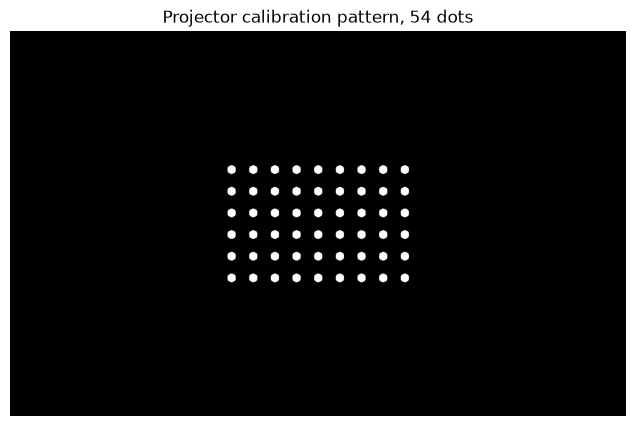

In [11]:
# A.1.1 of the handout: projector calibration pattern (grid of dots with known panel coordinates) and a white frame
# spacing 45 px: at 0.56 m one projector pixel is about 0.3 mm on the plate, so the 9 x 6 grid covers about 11 x 7 cm
# and must lie completely on the checkerboard plate in every pose
def generate_calibration_pattern(rows=6, cols=9, spacing=45, radius=9, shape=(800, 1280), path=PATTERN_DIR):
    """Saves a grid of white dots on black and returns the panel coordinates (rows*cols, 2) of the dot centers (row by row)"""
    h, w = shape
    xs = (w - (cols - 1) * spacing) / 2 + spacing * np.arange(cols)
    ys = (h - (rows - 1) * spacing) / 2 + spacing * np.arange(rows)
    centers = np.array([(x, y) for y in ys for x in xs], dtype=np.float64)

    yy, xx = np.mgrid[0:h, 0:w]
    pattern = np.zeros(shape, np.uint8)
    for x, y in centers:
        pattern[(xx - x) ** 2 + (yy - y) ** 2 <= radius ** 2] = 255

    os.makedirs(path, exist_ok=True)
    cv.imwrite(os.path.join(path, 'calibration-pattern.png'), pattern)
    cv.imwrite(os.path.join(path, 'white.png'), np.full(shape, 255, np.uint8))
    np.save(os.path.join(os.path.dirname(path), 'projector-calibration-points.npy'), centers)
    return pattern, centers

calib_pattern, calib_panel_points = generate_calibration_pattern()
plt.figure(figsize=(8, 5))
plt.imshow(calib_pattern, cmap='gray')
plt.title(f'Projector calibration pattern, {len(calib_panel_points)} dots')
plt.axis('off')
plt.show()

20 white-frame photos, 20 pattern photos
Poses shown in later steps: [0, 6, 13, 19]


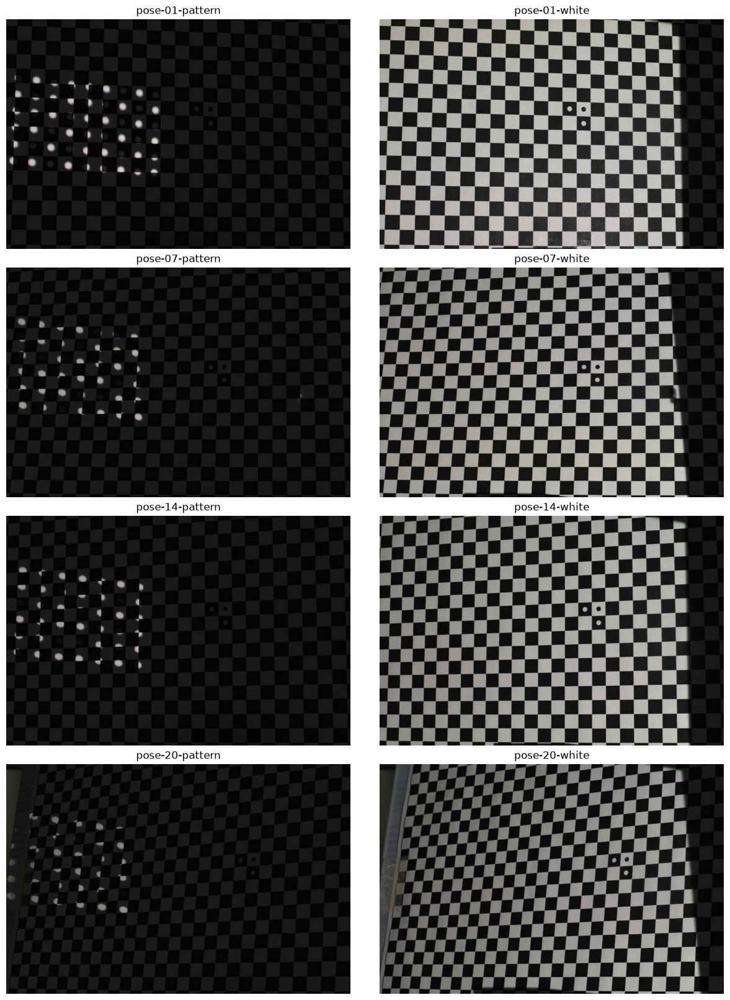

In [12]:
# TODO (A.2): Display four poses (white-frame photo and pattern photo of each); store the indexes of these four poses for later steps
# Expected output: 4 image pairs
calib_white_files = sorted(glob(os.path.join(CALIB_DIR, 'pose-*-white.JPG')))
calib_pattern_files = sorted(glob(os.path.join(CALIB_DIR, 'pose-*-pattern.JPG')))
print(f'{len(calib_white_files)} white-frame photos, {len(calib_pattern_files)} pattern photos')

if calib_white_files and len(calib_white_files) == len(calib_pattern_files):
    n_poses = len(calib_white_files)
    calib_display_idx = np.unique(np.linspace(0, n_poses - 1, 4).round().astype(int)).tolist()
    print('Poses shown in later steps:', calib_display_idx)
    pairs = {}
    for i in calib_display_idx:
        imgs = load_images([calib_white_files[i], calib_pattern_files[i]], display=False)
        pairs.update(imgs)
    display_images(pairs, cols=2)
else:
    calib_display_idx = []
    print('Calibration photos missing or unpaired in', CALIB_DIR)

### A.3  Scanning patterns  [max. 1 pt]

In [13]:
def generate_slset(n, shape=(800, 1280), path='setup-act/structured-light-patterns', x_range=None):
    """Generates the scanning patterns (one dark-light edge per pattern) and the panel coordinates of the upper and lower end of every edge

    Args:
        n: number of patterns (at least 20)
        shape: resolution of the projector panel
        path: folder where the patterns, a white and a black frame are saved
        x_range: (first, last) panel column where the light part starts; default: almost the whole panel (margin of 40 px)

    Returns:
        Array (2, n, 2) of panel points, as returned by load_projector_panel_points()
    """

    # OWN: NumPy array operations only (cv.imwrite only saves the files)
    h, w = shape
    if x_range is None:
        x_range = (40, w - 40)
    columns = np.round(np.linspace(x_range[0], x_range[1], n)).astype(int)

    # Pattern k: columns < columns[k] dark, columns >= columns[k] light; the edge lies on the pixel border x = columns[k] - 0.5
    patterns = np.where(np.arange(w)[None, None, :] >= columns[:, None, None], 255, 0).astype(np.uint8)
    patterns = np.broadcast_to(patterns, (n, h, w))

    edge_x = columns - 0.5
    upper = np.stack([edge_x, np.full(n, -0.5)], axis=1)     # upper end of the edge (top border of the panel)
    lower = np.stack([edge_x, np.full(n, h - 0.5)], axis=1)  # lower end of the edge (bottom border of the panel)

    os.makedirs(path, exist_ok=True)
    for k in range(n):
        cv.imwrite(os.path.join(path, f'pattern-{k + 1:02d}.png'), patterns[k])
    cv.imwrite(os.path.join(path, 'white.png'), np.full(shape, 255, np.uint8))
    cv.imwrite(os.path.join(path, 'black.png'), np.zeros(shape, np.uint8))
    np.save(os.path.join(os.path.dirname(path), 'panel_upper_points.npy'), upper)
    np.save(os.path.join(os.path.dirname(path), 'panel_lower_points.npy'), lower)

    return np.rollaxis(np.dstack((upper, lower)), 2, 0)

panel points: (2, 100, 2) (upper/lower, edge, xy)
saved: 100 patterns + white.png + black.png in setup-act\structured-light-patterns


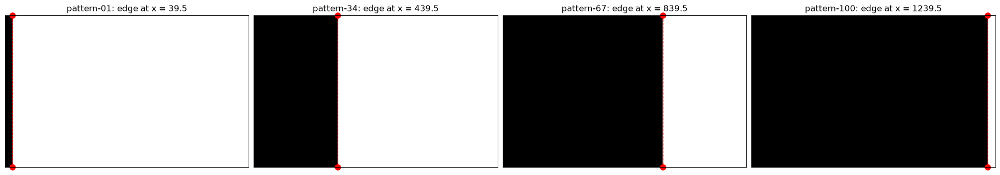

In [14]:
# TODO (A.3.2): Display four patterns with their panel points
# Expected output: 4 images
M = 100                        # number of edges; the scans were taken with this set: do not change it any more
EDGE_RANGE = (40, 1240)        # panel columns covered by the edges: from almost the left border to almost the right border
panel_points = generate_slset(M, path=PATTERN_DIR, x_range=EDGE_RANGE)
print('panel points:', panel_points.shape, '(upper/lower, edge, xy)')
print('saved:', len(glob(os.path.join(PATTERN_DIR, 'pattern-*.png'))), 'patterns + white.png + black.png in', PATTERN_DIR)

pattern_display_idx = np.linspace(0, M - 1, 4).round().astype(int)
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8), constrained_layout=True)
for ax, k in zip(axes, pattern_display_idx):
    ax.imshow(cv.imread(os.path.join(PATTERN_DIR, f'pattern-{k + 1:02d}.png'), cv.IMREAD_GRAYSCALE), cmap='gray', vmin=0, vmax=255)
    (xu, yu), (xl, yl) = panel_points[0, k], panel_points[1, k]
    ax.plot([xu, xl], [yu, yl], 'r--', lw=1)
    ax.plot([xu, xl], [yu, yl], 'ro', ms=8, clip_on=False)
    ax.set_title(f'pattern-{k + 1:02d}: edge at x = {xu:.1f}')
    ax.set_xticks([])
    ax.set_yticks([])  # keep the frame so that the white part of the panel stays visible
plt.show()

### A.4–A.5  Scans of the object and of the plane  [max. 2 pts]

object: 35 pattern photos (patterns 63–97, 35 with panel points in setup-act, edges at x = 791.5 … 1203.5), white: True, black: True


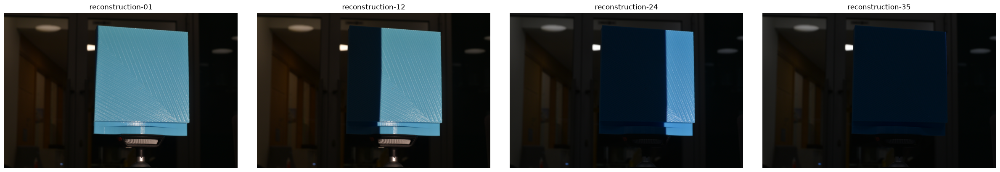

flat board: 35 pattern photos (patterns 63–97, 35 with panel points in setup-act, edges at x = 791.5 … 1203.5), white: True, black: True


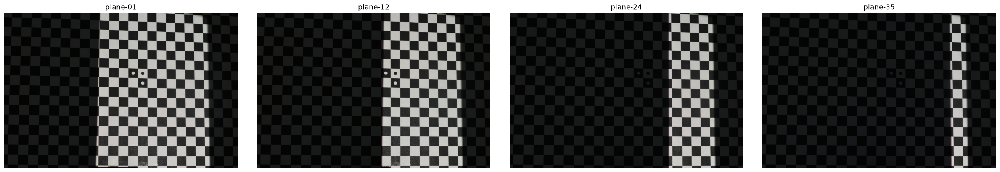

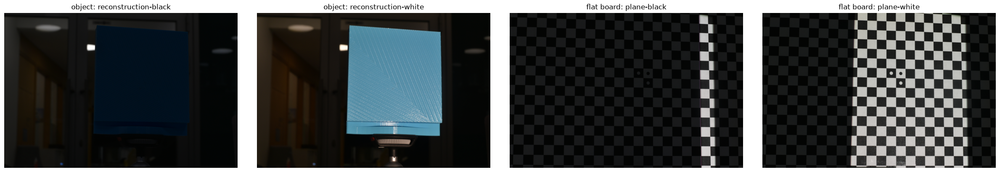

caliper width: 104.0 mm
caliper height: 116.0 mm


In [15]:
# TODO (A.4–A.5): Display four photos of each scan, and the white and black photos; print the two caliper measurements
# Expected output: 2 rows of 4 images + 4 images, 2 numbers
caliper_mm = {'width': 104.0, 'height': 116.0}  # caliper measurements of the object in mm

def load_scan(folder, prefix):
    """Returns (white files, black files, pattern photo files, pattern numbers) of one scan.

    A pattern photo is named <prefix>-<k>.JPG (or .jpg), where k is the number of the projected pattern,
    so photo <prefix>-63.JPG belongs to the edge panel_points[:, 62].
    """
    names = sorted(os.listdir(folder)) if os.path.isdir(folder) else []
    pick = lambda tag: [os.path.join(folder, f) for f in names if f.lower() in (f'{prefix}-{tag}.jpg', f'{prefix}-{tag}.jpeg')]
    files, numbers = [], []
    for f in names:
        stem, ext = os.path.splitext(f)
        tag = stem[len(prefix) + 1:] if stem.lower().startswith(prefix + '-') else ''
        if ext.lower() in ('.jpg', '.jpeg') and tag.isdigit():
            files.append(os.path.join(folder, f))
            numbers.append(int(tag))
    order = np.argsort(numbers)
    return pick('white'), pick('black'), [files[i] for i in order], np.array(numbers, dtype=int)[order]

def load_panel_points(folder):
    return load_projector_panel_points(os.path.join(folder, 'panel_upper_points.npy'), os.path.join(folder, 'panel_lower_points.npy'))

shown_scans = {'object': OBJECT_SCAN, 'flat board': PLANE_SCAN}
white_black = {}
for name, scan in shown_scans.items():
    white, black, files, numbers = load_scan(scan['folder'], scan['prefix'])
    if 'renumber' in scan:                       # photo number -> number of the projected pattern
        numbers = np.array([scan['renumber'](k) for k in numbers], dtype=int)
    panel = load_panel_points(scan['panel_dir'])
    print(f'{name}: {len(files)} pattern photos', end='')
    if len(numbers):
        known = numbers <= panel.shape[1]
        print(f' (patterns {numbers[0]}–{numbers[-1]}, {known.sum()} with panel points in {scan["panel_dir"]}, '
              f'edges at x = {panel[0, numbers[known][0] - 1, 0]:.1f} … {panel[0, numbers[known][-1] - 1, 0]:.1f})', end='')
    print(f', white: {bool(white)}, black: {bool(black)}')
    if files:
        show = np.linspace(0, len(files) - 1, 4).round().astype(int)
        display_images(load_images([files[i] for i in show], display=False), cols=4)
    imgs = load_images(white + black, display=False) if white or black else {}
    white_black.update({f'{name}: {k}': v for k, v in imgs.items()})
if white_black:
    display_images(white_black, cols=4)

for key, value in caliper_mm.items():
    print(f'caliper {key}: {value} mm' if value is not None else f'caliper {key}: not entered yet')

## B  Core processing  [8 pts]

### B.1  Reconstruction with the reference setup  [max. 3 pts]

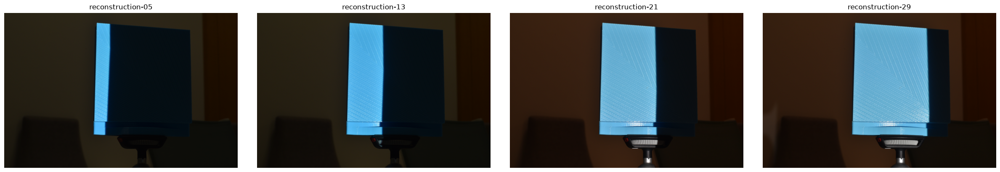

camera    intrinsic matrix   (3, 3)
camera    distortion vector  (1, 5)
camera    rotation matrix    (3, 3)
camera    translation vector (3, 1)
projector intrinsic matrix   (3, 3)
projector distortion vector  (1, 5)
projector rotation matrix    (3, 3)
projector translation vector (3, 1)
panel points          (2, 31, 2) (upper/lower, edge, xy)
reference data        setup-ref-1
scan photos           37 found, 36 with an edge; photos 1–31 used, full size (3000, 4496)
white / black frames  (3000, 4496) (3000, 4496) (photo 37 / per-pixel min of the edge photos)


In [16]:
# TODO (B.1.1): Load images, calibration data (load_calibration) and panel points (load_projector_panel_points) of the reference setup; select 4 images for display
# Expected output: 4 images, shapes of the loaded arrays
# Reference data: setup-ref-1 (updated version; setup-ref-2 is not used: its reconstruction-08.JPG is an empty file)
# 37 photos: 01-36 with an edge (light on the left, dark on the right), 37 = white frame.
# Only 31 panel points (x = 440...740) are given for the 36 edge photos (see the remark after B.1.5).
REF = 'setup-ref-1'
REF_WHITE_PHOTO = 37      # photo under the white frame (None: per-pixel maximum of the edge photos)
REF_FIRST_PHOTO = 1       # photos REF_FIRST_PHOTO ... REF_FIRST_PHOTO + 30 are paired with edges 1-31

ref_camera, ref_projector = load_calibration(os.path.join(REF, 'calibration-data'))
ref_panel_points = load_projector_panel_points(os.path.join(REF, 'panel_upper_points.npy'),
                                               os.path.join(REF, 'panel_lower_points.npy'))
ref_files = sorted(glob(os.path.join(REF, 'reconstruction-dataset', 'reconstruction-*.JPG')))

M_ref = ref_panel_points.shape[1]
ref_edge_files = [f for f in ref_files if REF_WHITE_PHOTO is None or not f.endswith(f'-{REF_WHITE_PHOTO:02d}.JPG')]
ref_scan_files = ref_edge_files[REF_FIRST_PHOTO - 1:REF_FIRST_PHOTO - 1 + M_ref]

def read_gray(name):
    """Grayscale photo at full resolution (the calibration data refers to full-resolution pixels), float32 in [0, 1]"""
    image = cv.cvtColor(cv.imread(name, cv.IMREAD_COLOR), cv.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return to_gray(image).astype(np.float32)

# white: the photo under the white frame (or the per-pixel maximum); black (no photo): per-pixel minimum of all edge photos
ref_black = read_gray(ref_edge_files[0])
ref_max = ref_black.copy()
for name in ref_edge_files[1:]:
    image = read_gray(name)
    np.minimum(ref_black, image, out=ref_black)
    np.maximum(ref_max, image, out=ref_max)
ref_white = ref_max if REF_WHITE_PHOTO is None else     read_gray(os.path.join(REF, 'reconstruction-dataset', f'reconstruction-{REF_WHITE_PHOTO:02d}.JPG'))
del ref_max

ref_display_idx = [4, 12, 20, 28]  # photos shown in all later steps (indexes into ref_scan_files)
ref_display = load_images([ref_scan_files[i] for i in ref_display_idx], display=False)
display_images(ref_display, cols=4)

names = ['intrinsic matrix', 'distortion vector', 'rotation matrix', 'translation vector']
for device, data in (('camera', ref_camera), ('projector', ref_projector)):
    for name, value in zip(names, data):
        print(f'{device:9s} {name:18s} {value.shape}')
print('panel points         ', ref_panel_points.shape, '(upper/lower, edge, xy)')
print(f'reference data        {REF}')
print(f'scan photos           {len(ref_files)} found, {len(ref_edge_files)} with an edge; '
      f'photos {REF_FIRST_PHOTO}–{REF_FIRST_PHOTO + M_ref - 1} used, full size {ref_white.shape}')
print('white / black frames ', ref_white.shape, ref_black.shape,
      f'({"photo " + str(REF_WHITE_PHOTO) if REF_WHITE_PHOTO else "per-pixel max"} / per-pixel min of the edge photos)')

**B.1.2 Purpose of the calibration data.** Each device (camera and projector) is described as a pinhole $\tilde{\mathbf x} \sim K(R\mathbf X + \mathbf t)$ plus lens distortion:

- **Intrinsic matrix $K$ (3×3):** the internal geometry of the device: focal lengths $f_x, f_y$ in pixels and the principal point $(c_x, c_y)$. It converts between pixel coordinates and viewing directions in the device frame ($K^{-1}\tilde{\mathbf x}$ is the direction of the ray of a pixel).
- **Distortion vector (1×5: $k_1, k_2, p_1, p_2, k_3$):** radial and tangential lens distortion. Pixels are undistorted with it before $K^{-1}$ is applied, so that the rays are straight lines.
- **Rotation matrix $R$ (3×3):** the orientation of the device: it turns world coordinates into device coordinates.
- **Translation vector $\mathbf t$ (3×1):** together with $R$ the position of the device; the center of projection is $\mathbf C = -R^\top \mathbf t$ in world coordinates (in mm, the world frame is the one of the calibration plate).

For the **camera** these data turn every detected edge pixel into a ray $\mathbf C_c + \lambda\,\mathbf d$; for the **projector** they turn the two end points of every projected edge into the plane of light through $\mathbf C_p$. The extrinsics $R, \mathbf t$ of both devices in the same world frame give the relative position of projector and camera (the baseline), which makes the triangulation possible.

In [17]:
def detect_edge(image, white, black, n=20, min_contrast=0.08, window=20, min_step=0.4):
    """Sub-pixel positions of the dark-light edge in a scan photo

    Args:
        image, white, black: grayscale photos under the pattern, the white and the black frame
        n: minimal number of points
        min_contrast: pixels with white - black below this value are ignored (shadows, background)
        window: number of pixels on each side used to check that a crossing is a real dark-light step
        min_step: minimal difference (in normalized intensity) between the mean right and the mean left of the crossing

    Returns:
        Array (N, 2) of sensor coordinates (x, y)
    """

    # OWN: NumPy array operations only
    image, white, black = (np.asarray(a, np.float64) for a in (image, white, black))
    contrast = white - black
    valid = contrast > min_contrast
    # normalized intensity: 0 under the black frame, 1 under the white frame, 0.5 on the edge
    v = np.where(valid, (image - black) / np.where(valid, contrast, 1.0), np.nan)

    h, w = v.shape
    left, right = v[:, :-1], v[:, 1:]
    crossing = (left < 0.5) & (right >= 0.5)  # dark on the left, light on the right

    # strength of every crossing: mean of the `window` pixels on the right minus mean of the `window` pixels on the left
    cumsum = np.concatenate([np.zeros((h, 1)), np.cumsum(np.nan_to_num(v), axis=1)], axis=1)
    x = np.arange(w - 1)
    lo = np.clip(x - window + 1, 0, w)
    hi = np.clip(x + 1 + window, 0, w)
    mean_left = (cumsum[:, x + 1] - cumsum[:, lo]) / (x + 1 - lo)
    mean_right = (cumsum[:, hi] - cumsum[:, x + 1]) / (hi - x - 1)
    strength = np.where(crossing, mean_right - mean_left, -np.inf)

    # in every row keep the strongest crossing, if it is a real step
    rows = np.arange(h)
    best = np.argmax(strength, axis=1)
    keep = strength[rows, best] > min_step
    rows, best = rows[keep], best[keep]

    # linear interpolation between the two pixels around the crossing
    a, b = left[rows, best], right[rows, best]
    xs = best + (0.5 - a) / (b - a)
    points = np.column_stack([xs, rows.astype(np.float64)])
    if len(points) < n:
        print(f'detect_edge: only {len(points)} points found (at least {n} wanted)')
    return points

detect_edge: only 5 points found (at least 20 wanted)


points per photo: min 5, median 2169, max 2616; total 66777
photos with fewer than 20 points: [1] (edge outside the region that is lit in some photos and dark in others)


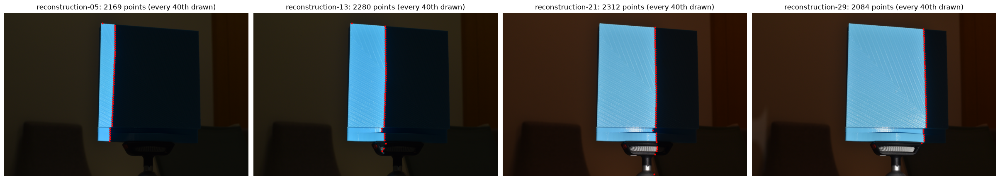

In [18]:
# TODO (B.1.3): Draw the detected points on the four images
# Expected output: 4 images
# The updated reference photos show the edge the other way round (light on the left, dark on the right). Mirroring the
# photos left-right turns it into a dark-light edge for detect_edge; the x coordinates are mirrored back afterwards.
REF_LIGHT_ON_LEFT = True
def detect_ref_edge(image):
    if not REF_LIGHT_ON_LEFT:
        return detect_edge(image, ref_white, ref_black)
    points = detect_edge(image[:, ::-1], ref_white[:, ::-1], ref_black[:, ::-1])
    points[:, 0] = image.shape[1] - 1 - points[:, 0]
    return points

ref_sensor_points = [detect_ref_edge(read_gray(name)) for name in ref_scan_files]
counts = np.array([len(p) for p in ref_sensor_points])
print(f'points per photo: min {counts.min()}, median {int(np.median(counts))}, max {counts.max()}; total {counts.sum()}')
print('photos with fewer than 20 points:', [int(i) + 1 for i in np.where(counts < 20)[0]] or 'none',
      '(edge outside the region that is lit in some photos and dark in others)')

fig, axes = plt.subplots(1, 4, figsize=(24, 4.6), constrained_layout=True)
for ax, i, (caption, image) in zip(axes, ref_display_idx, ref_display.items()):
    scale = image.shape[1] / ref_white.shape[1]          # displayed photos are downsized
    p = ref_sensor_points[i][::40]                       # every 40th point, for visibility
    ax.imshow(np.clip(image, 0, 1))
    ax.plot((p[:, 0] + 0.5) * scale - 0.5, (p[:, 1] + 0.5) * scale - 0.5, 'r.', ms=4)
    ax.set_title(f'{caption}: {len(ref_sensor_points[i])} points (every 40th drawn)')
    ax.axis('off')
plt.show()

In [19]:
def pixel_to_ray(K, dist, R, t, points):
    """Rays of pixels in world coordinates (P.1)

    Args:
        K, dist, R, t: calibration data of the device
        points: array (N, 2) of pixel coordinates

    Returns:
        (center C, array (N, 3) of directions d)
    """

    # OWN: NumPy array operations only (cv.undistortPoints is allowed)
    points = np.asarray(points, np.float64).reshape(-1, 1, 2)
    undistorted = cv.undistortPoints(points, K, dist, P=K).reshape(-1, 2)  # undistorted pixel coordinates
    x = np.column_stack([undistorted, np.ones(len(undistorted))])          # homogeneous pixels (x, y, 1)
    d = (R.T @ np.linalg.inv(K) @ x.T).T                                    # d = R^T K^-1 x
    C = -R.T @ np.asarray(t, np.float64).reshape(3)                         # C = -R^T t
    return C, d

In [20]:
# B.1.4: rays of the camera points of one photo and of the panel points of the corresponding edge
k = ref_display_idx[0]
Cc, dc = pixel_to_ray(*ref_camera, ref_sensor_points[k])
Cp, dp = pixel_to_ray(*ref_projector, ref_panel_points[:, k, :])
print('camera center    C_c =', Cc.round(1), 'mm')
print('projector center C_p =', Cp.round(1), 'mm')
print(f'baseline |C_p - C_c| = {np.linalg.norm(Cp - Cc):.1f} mm')
print(f'photo {k + 1}: {len(dc)} camera rays, directions', dc.shape, '; edge', k + 1, ': 2 projector rays', dp.shape)

camera center    C_c = [ -92.4 -111.7  612.3] mm
projector center C_p = [  75.9 -163.7  605.1] mm
baseline |C_p - C_c| = 176.3 mm
photo 5: 2169 camera rays, directions (2169, 3) ; edge 5 : 2 projector rays (2, 3)


In [21]:
def intersect(C, d, plane_point, plane_normal):
    """Intersection of rays with a plane (P.2)

    Args:
        C: ray origin
        d: array (N, 3) of ray directions
        plane_point, plane_normal: the plane

    Returns:
        Array (N, 3) of intersection points
    """

    # OWN: NumPy array operations only
    # lambda = n . (P0 - C) / (n . d); rays parallel to the plane give NaN
    C, d = np.asarray(C, np.float64), np.atleast_2d(np.asarray(d, np.float64))
    n = np.asarray(plane_normal, np.float64)
    denominator = d @ n
    parallel = np.abs(denominator) < 1e-12 * np.linalg.norm(d, axis=1) * np.linalg.norm(n)
    lam = ((np.asarray(plane_point, np.float64) - C) @ n) / np.where(parallel, np.nan, denominator)
    return C + lam[:, None] * d

In [22]:
def reconstruct(sensor_points, panel_points, camera, projector):
    """Point cloud from edge points and panel points

    Args:
        sensor_points: list of M arrays (N, 2)
        panel_points: array (2, M, 2)
        camera, projector: calibration data lists

    Returns:
        Array of 3D points
    """

    clouds = []
    for m, points in enumerate(sensor_points):
        if len(points) == 0:
            continue
        Cp, dp = pixel_to_ray(*projector, panel_points[:, m, :])  # rays of the upper and the lower end of edge m
        normal = np.cross(dp[0], dp[1])                            # plane of light (P.2.1)
        Cc, dc = pixel_to_ray(*camera, points)                     # camera rays (P.1.2)
        clouds.append(intersect(Cc, dc, Cp, normal))               # ray-plane intersection (P.2.2)
    cloud = np.concatenate(clouds) if clouds else np.zeros((0, 3))
    return cloud[np.isfinite(cloud).all(axis=1)]


def remove_outliers(cloud, k=6.0):
    """Keeps the points within k robust standard deviations (MAD) of the median in every coordinate"""
    median = np.median(cloud, axis=0)
    mad = 1.4826 * np.median(np.abs(cloud - median), axis=0)
    return cloud[(np.abs(cloud - median) <= k * mad).all(axis=1)]


def show_cloud(cloud, views=((25, -60), (5, -90)), title='', max_points=30000):
    """Displays a point cloud (mm) from several viewpoints with equal axis scales, colored by z"""
    p = cloud[:: max(1, len(cloud) // max_points)]
    fig = plt.figure(figsize=(8 * len(views), 7), constrained_layout=True)
    for k, (elev, azim) in enumerate(views):
        ax = fig.add_subplot(1, len(views), k + 1, projection='3d')
        sc = ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=p[:, 2], s=0.5, cmap='viridis')
        ax.set_box_aspect(np.ptp(p, axis=0))
        ax.view_init(elev, azim)
        ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.set_zlabel('z [mm]')
        ax.set_title(f'{title} (elevation {elev}°, azimuth {azim}°)')
    fig.colorbar(sc, ax=fig.axes, shrink=0.6, label='z [mm]')
    plt.show()

reconstructed points: 66777, after removing 258 outliers: 66519
extent of the cloud [mm]: x 54.4  y 100.4  z 31.3


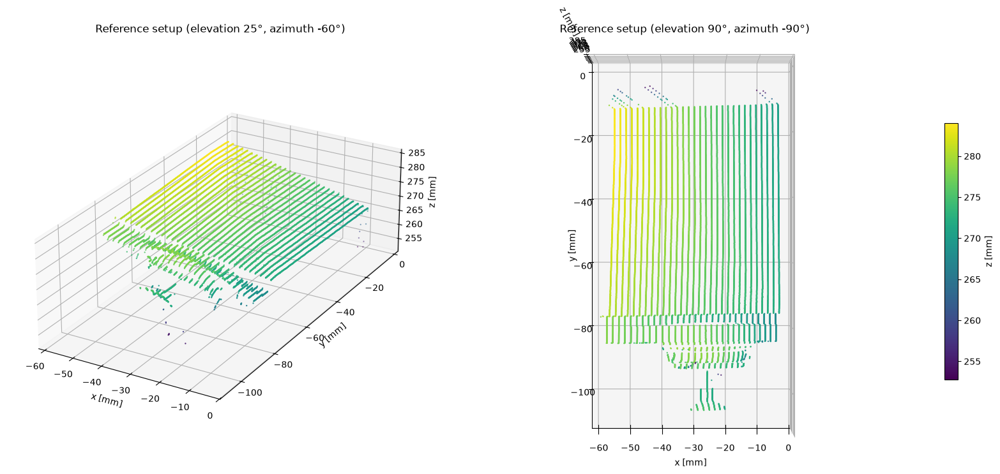

In [23]:
# TODO (B.1.5): Reconstruct all points of all images; display the point cloud from two viewpoints
# Expected output: 2 views, number of points (at least 400)
ref_cloud_raw = reconstruct(ref_sensor_points, ref_panel_points, ref_camera, ref_projector)
ref_cloud = remove_outliers(ref_cloud_raw)
print(f'reconstructed points: {len(ref_cloud_raw)}, after removing {len(ref_cloud_raw) - len(ref_cloud)} outliers: {len(ref_cloud)}')
print('extent of the cloud [mm]: x', np.ptp(ref_cloud[:, 0]).round(1), ' y', np.ptp(ref_cloud[:, 1]).round(1), ' z', np.ptp(ref_cloud[:, 2]).round(1))
show_cloud(ref_cloud, views=((25, -60), (90, -90)), title='Reference setup')

**Remark on the reference reconstruction.** The pipeline runs on the reference data (about 66 500 points; baseline from the reference calibration 176.3 mm), but the object comes out smaller and closer to the camera than it is (front face about 90 mm high instead of 116 mm, about 350 mm from the camera instead of about 600 mm). The reference folder has 36 edge photos but only 31 panel points; pairing the photos with the edges with any offset (photos 1–31 … 6–36) or mirroring the panel points does not give a consistent size, so the provided panel points most likely do not belong to this scan. The same code gives the correct size with my own data (C.1: baseline 183 mm against 180 mm measured; object 97 × 124 mm against 104 × 116 mm).

### B.2  Calibration of the camera  [max. 2 pts]

pose  1: 21 x 16 inner corners, marker at corner (5, 6)


pose  2: 21 x 16 inner corners, marker at corner (5, 6)


pose  3: 20 x 16 inner corners, marker at corner (5, 6)


pose  4: 21 x 17 inner corners, marker at corner (6, 6)


pose  5: 22 x 16 inner corners, marker at corner (5, 6)


...

pose 16: 19 x 16 inner corners, marker at corner (5, 8)


pose 17: 26 x 13 inner corners, marker at corner (2, 9)


pose 18: only 7 x 5 corners, marker not found, pose skipped


pose 19: 21 x 16 inner corners, marker at corner (6, 3)


pose 20: 25 x 16 inner corners, marker at corner (6, 3)
checkerboard found in 17 of 20 poses


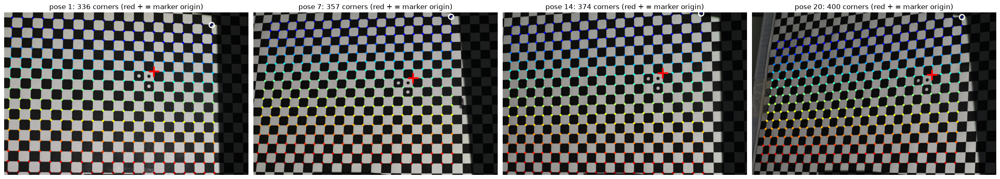

In [24]:
# TODO (B.2.1): Detect the corners of the printed checkerboard in the white-frame photos; draw them on the four selected photos
# Expected output: 4 images
CHESSBOARD_MIN = (7, 5)  # minimal number of inner corners (columns, rows) that must be visible; the plate may show more
SQUARE_MM = 10.0         # cell size of the printed checkerboard
DETECT_MAX_SIDE = 2000   # larger photos are searched downsized, the corners are then refined at full size

def detect_chessboard(gray):
    """Inner corners of the checkerboard.

    Returns (corners (rows, cols, 2) in pixels, origin (row, col) of the three-dot marker or None), or (None, None).
    """
    image = np.clip(gray * 255, 0, 255).astype(np.uint8)
    scale = min(1.0, DETECT_MAX_SIDE / max(image.shape))
    small = cv.resize(image, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA) if scale < 1 else image
    base = cv.CALIB_CB_EXHAUSTIVE | cv.CALIB_CB_ACCURACY | cv.CALIB_CB_LARGER
    for flags in (base | cv.CALIB_CB_MARKER, base):            # with the marker first, then without it
        ok, corners, meta = cv.findChessboardCornersSBWithMeta(small, CHESSBOARD_MIN, flags)
        if ok:
            break
    if not ok:
        return None, None
    corners = corners.reshape(-1, 2).astype(np.float32)
    if scale < 1:
        corners = (corners + 0.5) / scale - 0.5
        criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 50, 1e-3)
        corners = cv.cornerSubPix(image, corners.reshape(-1, 1, 2), (11, 11), (-1, -1), criteria).reshape(-1, 2)
    rows, cols = meta.shape
    marker = np.argwhere(meta == 4)                              # 4: corner at the marker (pattern origin)
    return corners.reshape(rows, cols, 2), (tuple(int(v) for v in marker[0]) if len(marker) else None)

if not calib_white_files:
    print('No calibration photos yet: B.2 and B.3 are skipped.')
    cb_corners, cb_origin = {}, {}
else:
    cb_corners, cb_origin = {}, {}
    for i, name in enumerate(calib_white_files):
        corners, origin = detect_chessboard(read_gray(name))
        if corners is None:
            print(f'pose {i + 1:2d}: checkerboard NOT found ({os.path.basename(name)}), pose skipped')
            continue
        if origin is None:
            # without the marker only a part of the board was found and its corners were numbered wrongly
            # (tens of pixels of reprojection error in a first test), so these detections are not used
            print(f'pose {i + 1:2d}: only {corners.shape[1]} x {corners.shape[0]} corners, marker not found, pose skipped')
            continue
        cb_corners[i], cb_origin[i] = corners, origin
        print(f'pose {i + 1:2d}: {corners.shape[1]} x {corners.shape[0]} inner corners, marker at corner {origin}')
    print(f'checkerboard found in {len(cb_corners)} of {len(calib_white_files)} poses')

    shown = [i for i in calib_display_idx if i in cb_corners]
    fig, axes = plt.subplots(1, len(shown), figsize=(6 * len(shown), 4.5), squeeze=False, constrained_layout=True)
    for ax, i in zip(axes[0], shown):
        image = load_images([calib_white_files[i]], display=False, max_side=None).popitem()[1]
        c = cb_corners[i].reshape(-1, 2)
        ax.imshow(image)
        ax.scatter(c[:, 0], c[:, 1], c=np.arange(len(c)), cmap='jet', s=8)   # color = order of the corners
        ax.plot(*cb_corners[i][0, 0], 'wo', ms=9, mfc='none', mew=2)
        if cb_origin[i]:
            ax.plot(*cb_corners[i][cb_origin[i]], 'r+', ms=18, mew=3)
        ax.set_title(f'pose {i + 1}: {len(c)} corners (red + = marker origin)')
        ax.axis('off')
    plt.show()

In [25]:
# TODO (B.2.2): World coordinates of the detected corners (three-dot marker = origin, plate = plane z = 0, cell size 10 mm), in the order of the detected corners
# Expected output: shapes of the point arrays
cb_world = {}
for i, corners in cb_corners.items():
    rows, cols = corners.shape[:2]
    r0, c0 = cb_origin[i] if cb_origin[i] else (0, 0)       # without a marker: the first detected corner
    r, c = np.mgrid[0:rows, 0:cols]
    cb_world[i] = np.column_stack([(c - c0).ravel() * SQUARE_MM, (r - r0).ravel() * SQUARE_MM,
                                   np.zeros(rows * cols)]).astype(np.float32)
    print(f'pose {i + 1:2d}: image points {corners.reshape(-1, 2).shape}, world points {cb_world[i].shape}, '
          f'x {cb_world[i][:, 0].min():.0f}…{cb_world[i][:, 0].max():.0f} mm, y {cb_world[i][:, 1].min():.0f}…{cb_world[i][:, 1].max():.0f} mm')
if any(o is None for o in cb_origin.values()):
    print('Note: where the marker was not found, the first corner is the origin. Each pose has its own plate frame, '
          'so this does not change the calibration.')

pose  1: image points (336, 2), world points (336, 3), x -60…140 mm, y -50…100 mm
pose  2: image points (336, 2), world points (336, 3), x -60…140 mm, y -50…100 mm
pose  3: image points (320, 2), world points (320, 3), x -60…130 mm, y -50…100 mm
pose  4: image points (357, 2), world points (357, 3), x -60…140 mm, y -60…100 mm
pose  5: image points (352, 2), world points (352, 3), x -60…150 mm, y -50…100 mm
pose  6: image points (352, 2), world points (352, 3), x -60…150 mm, y -50…100 mm
pose  7: image points (357, 2), world points (357, 3), x -40…160 mm, y -70…90 mm
pose  8: image points (336, 2), world points (336, 3), x -60…140 mm, y -50…100 mm
pose  9: image points (368, 2), world points (368, 3), x -70…150 mm, y -50…100 mm
pose 11: image points (315, 2), world points (315, 3), x -60…140 mm, y -50…90 mm
pose 13: image points (357, 2), world points (357, 3), x -60…140 mm, y -60…100 mm
pose 14: image points (374, 2), world points (374, 3), x -40…170 mm, y -60…100 mm
pose 15: image poi

In [26]:
# TODO (B.2.3): Calibrate the camera; store the pose of the plate for every photo
# Expected output: intrinsic matrix, distortion coefficients, reprojection error
cam_poses = {}  # pose index -> (R, t) of the plate: plate coordinates -> camera coordinates
if cb_corners:
    poses = sorted(cb_corners)
    calib_image_size = read_gray(calib_white_files[poses[0]]).shape[::-1]   # (width, height)

    def per_pose_errors(poses, K, dist, rvecs, tvecs):
        errors = []
        for i, rvec, tvec in zip(poses, rvecs, tvecs):
            projected = cv.projectPoints(cb_world[i], rvec, tvec, K, dist)[0].reshape(-1, 2)
            errors.append(np.sqrt(np.mean(np.sum((projected - cb_corners[i].reshape(-1, 2)) ** 2, axis=1))))
        return np.array(errors)

    # calibrate, remove poses whose error is far above the others (> 3 x median and > 1 px), calibrate again
    while True:
        object_points = [cb_world[i] for i in poses]
        image_points = [cb_corners[i].reshape(-1, 1, 2).astype(np.float32) for i in poses]
        cam_rms, cam_K, cam_dist, rvecs, tvecs = cv.calibrateCamera(object_points, image_points, calib_image_size, None, None,
                                                                    flags=cv.CALIB_FIX_K3)
        errors = per_pose_errors(poses, cam_K, cam_dist, rvecs, tvecs)
        outliers = [i for i, e in zip(poses, errors) if e > max(3 * np.median(errors), 1.0)]
        if not outliers:
            break
        print('removed (reprojection error far above the others): poses', [i + 1 for i in outliers])
        poses = [i for i in poses if i not in outliers]
    for i, rvec, tvec in zip(poses, rvecs, tvecs):
        cam_poses[i] = (cv.Rodrigues(rvec)[0], tvec.reshape(3, 1))

    np.set_printoptions(suppress=True, precision=3)
    print('photo size:', calib_image_size)
    print('intrinsic matrix K:\n', cam_K)
    print('distortion coefficients (k1, k2, p1, p2, k3):', cam_dist.ravel())
    print(f'RMS reprojection error: {cam_rms:.3f} px ({len(poses)} poses, k3 fixed to 0)')
    for i, error, tvec in zip(poses, errors, tvecs):
        print(f'  pose {i + 1:2d}: reprojection error {error:.3f} px, plate at {np.linalg.norm(tvec):.0f} mm')
else:
    print('No checkerboard detections: camera not calibrated.')

photo size: (1620, 1080)
intrinsic matrix K:
 [[3891.7      0.     801.168]
 [   0.    3892.852  467.278]
 [   0.       0.       1.   ]]
distortion coefficients (k1, k2, p1, p2, k3): [-0.14  -0.033 -0.003 -0.     0.   ]
RMS reprojection error: 0.762 px (17 poses, k3 fixed to 0)
  pose  1: reprojection error 0.503 px, plate at 581 mm
  pose  2: reprojection error 0.525 px, plate at 581 mm
  pose  3: reprojection error 1.437 px, plate at 581 mm
  pose  4: reprojection error 0.578 px, plate at 607 mm
  pose  5: reprojection error 0.542 px, plate at 579 mm
  pose  6: reprojection error 0.568 px, plate at 576 mm
  pose  7: reprojection error 0.558 px, plate at 608 mm
  pose  8: reprojection error 0.508 px, plate at 566 mm
  pose  9: reprojection error 0.537 px, plate at 587 mm
  pose 11: reprojection error 0.581 px, plate at 574 mm
  pose 13: reprojection error 0.538 px, plate at 618 mm
  pose 14: reprojection error 0.586 px, plate at 593 mm
  pose 15: reprojection error 0.805 px, plate at 

In [27]:
# B.2.4: numbers for the check below
if cam_poses:
    sensor_width_px = 6000                                     # Nikon D5600: 6000 x 4000 pixels of 3.9 um
    f_expected = focal_length_mm * 1e-3 / (pixel_pitch_um * 1e-6) * calib_image_size[0] / sensor_width_px
    w, h = calib_image_size
    print(f'focal length: fx = {cam_K[0, 0]:.0f} px, fy = {cam_K[1, 1]:.0f} px; expected for a {focal_length_mm:.0f} mm lens and '
          f'{pixel_pitch_um} um pixels at {w} px width: {f_expected:.0f} px ({100 * (cam_K[0, 0] / f_expected - 1):+.1f} %)')
    print(f'principal point: ({cam_K[0, 2]:.0f}, {cam_K[1, 2]:.0f}) px; image center ({(w - 1) / 2:.0f}, {(h - 1) / 2:.0f}) px; '
          f'offset ({cam_K[0, 2] - (w - 1) / 2:+.0f}, {cam_K[1, 2] - (h - 1) / 2:+.0f}) px = '
          f'({100 * (cam_K[0, 2] - (w - 1) / 2) / w:+.1f} %, {100 * (cam_K[1, 2] - (h - 1) / 2) / h:+.1f} %) of the image size')

focal length: fx = 3892 px, fy = 3893 px; expected for a 50 mm lens and 3.9 um pixels at 1620 px width: 3462 px (+12.4 %)
principal point: (801, 467) px; image center (810, 540) px; offset (-8, -72) px = (-0.5 %, -6.7 %) of the image size


**B.2.4 Is the focal length consistent with a 50 mm lens and the pixel pitch? Is the principal point near the center?**

The photos are 1620 px wide (the 6000 px sensor of the D5600 downsized by 0.27), so a 50 mm lens with 3.9 µm pixels gives $f = 50\,\text{mm} / 3.9\,\mu\text{m} \times 1620/6000 = 3462$ px. The calibration gives $f_x = 3892$ px and $f_y = 3893$ px, 12.4 % more. Most of this difference is expected: the lens is focused on the plate at about 0.58 m, and the image distance is then $v = f\,u/(u - f) = 50 \times 580 / 530 \approx 54.7$ mm instead of 50 mm (+9.4 %), which gives an expected 3790 px. The remaining 2.7 % is within the tolerance of the nominal focal length of the lens. $f_x \approx f_y$, as expected for square pixels.

The principal point is at (801, 467) px; the image center is (809.5, 539.5) px. The offset is (−8, −72) px, i.e. 0.5 % of the width and 6.7 % of the height, which is normal for a real lens–sensor assembly (and for a principal point estimated from plate poses of moderate tilt).

### B.3  Calibration of the projector and of the pair  [max. 2 pts]

pose  5: dot grid NOT found (pose-05-pattern.JPG), pose skipped for the projector (all 54 dots must be in the photo and on the plate)


pose  6: dot grid NOT found (pose-06-pattern.JPG), pose skipped for the projector (all 54 dots must be in the photo and on the plate)


pose  7: dot grid NOT found (pose-07-pattern.JPG), pose skipped for the projector (all 54 dots must be in the photo and on the plate)


pose  8: dot grid NOT found (pose-08-pattern.JPG), pose skipped for the projector (all 54 dots must be in the photo and on the plate)


pose  9: dot grid NOT found (pose-09-pattern.JPG), pose skipped for the projector (all 54 dots must be in the photo and on the plate)


pose 11: dot grid NOT found (pose-11-pattern.JPG), pose skipped for the projector (all 54 dots must be in the photo and on the plate)


pose 13: dot grid NOT found (pose-13-pattern.JPG), pose skipped for the projector (all 54 dots must be in the photo and on the plate)


pose 14: dot grid NOT found (pose-14-pattern.JPG), pose skipped for the projector (all 54 dots must be in the photo and on the plate)


pose 19: dot grid NOT found (pose-19-pattern.JPG), pose skipped for the projector (all 54 dots must be in the photo and on the plate)


pose 20: dot grid NOT found (pose-20-pattern.JPG), pose skipped for the projector (all 54 dots must be in the photo and on the plate)
dot grid found in 7 of 17 calibrated poses


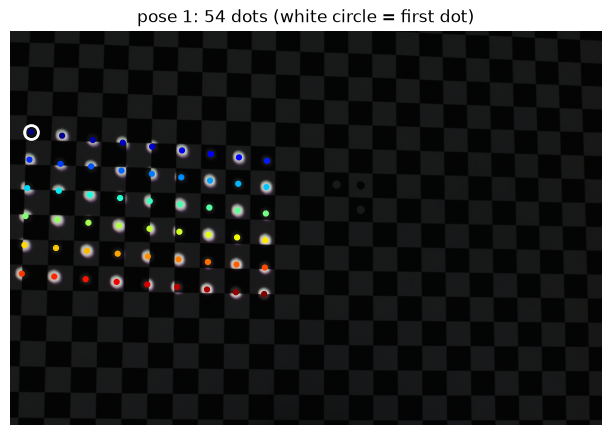

In [28]:
# TODO (B.3.1): Detect the features of the projected pattern in the second photo of every pose; draw them on the four selected photos
# Expected output: 4 images
PROJ_GRID = (9, 6)               # columns, rows of the dot grid of generate_calibration_pattern()
PROJECTOR_UPSIDE_DOWN = False    # True if the projector is mounted upside down (panel top appears at the bottom of the photo)
proj_panel_points = np.load(os.path.join(ACT, 'projector-calibration-points.npy')).astype(np.float32)  # row by row

def detect_projected_dots(pattern, white):
    """Centers (rows*cols, 2) of the projected dots in the order of proj_panel_points, or None"""
    # region lit by the projector: a maximum filter wider than a checker cell lets the black cells take the level of their
    # white neighbours; outside this region pattern / white is only noise and the checker cells look like dots
    k = int(round(white.shape[1] / 20)) | 1
    level = cv.dilate(white, np.ones((k, k), np.uint8))
    lit = level > 0.4 * np.percentile(level, 99)
    lit = cv.erode(lit.astype(np.uint8), np.ones((k + 20, k + 20), np.uint8)).astype(bool)
    ratio = np.where(lit & (white > 0.003), pattern / np.maximum(white, 1e-6), 0)  # divides out the printed checkerboard
    ratio = cv.GaussianBlur(np.clip(ratio, 0, 1.2).astype(np.float32), (0, 0), 1.5)
    image = np.clip(255 - ratio / 1.2 * 255, 0, 255).astype(np.uint8)   # dots dark on a light background

    params = cv.SimpleBlobDetector_Params()
    params.filterByColor, params.blobColor = True, 0
    params.filterByArea, params.minArea, params.maxArea = True, 15, 0.01 * image.size
    params.filterByCircularity, params.minCircularity = True, 0.5
    params.filterByInertia, params.minInertiaRatio = True, 0.2
    params.filterByConvexity, params.minConvexity = True, 0.8
    params.minThreshold, params.maxThreshold, params.thresholdStep = 20, 160, 10   # only strongly lit blobs (ratio > ~0.4)
    detector = cv.SimpleBlobDetector_create(params)
    for flags in (cv.CALIB_CB_SYMMETRIC_GRID, cv.CALIB_CB_SYMMETRIC_GRID | cv.CALIB_CB_CLUSTERING):
        ok, centers = cv.findCirclesGrid(image, PROJ_GRID, flags=flags, blobDetector=detector)
        if ok:
            break
    if not ok:
        return None
    grid = centers.reshape(PROJ_GRID[1], PROJ_GRID[0], 2)
    # order like the panel points: first row at the top of the panel, each row from left to right
    if grid[:, 0, 0].mean() > grid[:, -1, 0].mean():
        grid = grid[:, ::-1]
    if grid[0, :, 1].mean() > grid[-1, :, 1].mean():
        grid = grid[::-1]
    if PROJECTOR_UPSIDE_DOWN:
        grid = grid[::-1, ::-1]
    return grid.reshape(-1, 2).astype(np.float32)

proj_dots = {}
for i in sorted(cam_poses):
    dots = detect_projected_dots(read_gray(calib_pattern_files[i]), read_gray(calib_white_files[i]))
    if dots is None:
        print(f'pose {i + 1:2d}: dot grid NOT found ({os.path.basename(calib_pattern_files[i])}), pose skipped for the projector '
              f'(all {PROJ_GRID[0] * PROJ_GRID[1]} dots must be in the photo and on the plate)')
    else:
        proj_dots[i] = dots
print(f'dot grid found in {len(proj_dots)} of {len(cam_poses)} calibrated poses' if cam_poses else 'No calibrated poses yet.')

shown = [i for i in calib_display_idx if i in proj_dots]
if shown:
    fig, axes = plt.subplots(1, len(shown), figsize=(6 * len(shown), 4.5), squeeze=False, constrained_layout=True)
    for ax, i in zip(axes[0], shown):
        image = load_images([calib_pattern_files[i]], display=False, max_side=None).popitem()[1]
        ax.imshow(image)
        ax.scatter(proj_dots[i][:, 0], proj_dots[i][:, 1], c=np.arange(len(proj_dots[i])), cmap='jet', s=12)
        ax.plot(*proj_dots[i][0], 'wo', ms=10, mfc='none', mew=2)
        ax.set_title(f'pose {i + 1}: {len(proj_dots[i])} dots (white circle = first dot)')
        ax.axis('off')
    plt.show()

In [29]:
# TODO (B.3.2): World coordinates of the features: intersect their camera rays with the plane of the plate (pixel_to_ray, intersect)
# Expected output: shapes; plate residuals
proj_world = {}
for i, dots in proj_dots.items():
    R, t = cam_poses[i]                                          # world = plate frame of this pose
    C, d = pixel_to_ray(cam_K, cam_dist, R, t, dots)
    points = intersect(C, d, np.zeros(3), np.array([0.0, 0.0, 1.0]))
    # check: back into the photo, and distance from the plate
    projected = cv.projectPoints(points, cv.Rodrigues(R)[0], t, cam_K, cam_dist)[0].reshape(-1, 2)
    error = np.sqrt(np.mean(np.sum((projected - dots) ** 2, axis=1)))
    proj_world[i] = points.astype(np.float32)
    print(f'pose {i + 1:2d}: dots {dots.shape} -> world points {points.shape}; |z| max {np.abs(points[:, 2]).max():.1e} mm, '
          f'back-projection error {error:.2e} px, dots span {np.ptp(points[:, 0]):.0f} x {np.ptp(points[:, 1]):.0f} mm')

pose  1: dots (54, 2) -> world points (54, 3); |z| max 0.0e+00 mm, back-projection error 2.87e-10 px, dots span 97 x 63 mm
pose  2: dots (54, 2) -> world points (54, 3); |z| max 0.0e+00 mm, back-projection error 1.89e-10 px, dots span 93 x 60 mm
pose  3: dots (54, 2) -> world points (54, 3); |z| max 0.0e+00 mm, back-projection error 1.47e-10 px, dots span 91 x 59 mm
pose  4: dots (54, 2) -> world points (54, 3); |z| max 0.0e+00 mm, back-projection error 3.24e-10 px, dots span 95 x 65 mm
pose 15: dots (54, 2) -> world points (54, 3); |z| max 5.7e-14 mm, back-projection error 2.08e-11 px, dots span 85 x 51 mm
pose 16: dots (54, 2) -> world points (54, 3); |z| max 5.7e-14 mm, back-projection error 5.39e-11 px, dots span 91 x 57 mm
pose 17: dots (54, 2) -> world points (54, 3); |z| max 5.7e-14 mm, back-projection error 1.08e-11 px, dots span 90 x 56 mm


In [30]:
# TODO (B.3.3): Calibrate the projector as an inverse camera
# Expected output: intrinsic matrix, reprojection error
PROJECTOR_SIZE = (1280, 800)
proj_poses = {}
if len(proj_world) >= 3:
    poses = sorted(proj_world)
    object_points = [proj_world[i] for i in poses]
    image_points = [proj_panel_points.reshape(-1, 1, 2) for _ in poses]
    # The dot grid covers only a small part of the panel and only a few poses see all dots, so lens distortion and two
    # independent focal lengths are not determined (a free fit gave f = 23000 / 67000 px). Projector model: square pixels
    # (fx = fy) and no lens distortion; the start values only need to be plausible (the result is the same for any of them).
    K_start = np.array([[2000.0, 0, PROJECTOR_SIZE[0] / 2], [0, 2000.0, 0.75 * PROJECTOR_SIZE[1]], [0, 0, 1]])
    flags = (cv.CALIB_USE_INTRINSIC_GUESS | cv.CALIB_FIX_ASPECT_RATIO | cv.CALIB_ZERO_TANGENT_DIST |
             cv.CALIB_FIX_K1 | cv.CALIB_FIX_K2 | cv.CALIB_FIX_K3)
    proj_rms, proj_K, proj_dist, rvecs, tvecs = cv.calibrateCamera(object_points, image_points, PROJECTOR_SIZE, K_start, None,
                                                                   flags=flags)
    for i, rvec, tvec in zip(poses, rvecs, tvecs):
        proj_poses[i] = (cv.Rodrigues(rvec)[0], tvec.reshape(3, 1))
    print('projector intrinsic matrix:\n', proj_K)
    print('distortion coefficients (k1, k2, p1, p2, k3):', proj_dist.ravel())
    print(f'RMS reprojection error: {proj_rms:.3f} px (projector pixels), {len(poses)} poses')
else:
    print(f'Projector not calibrated: dot grids found in {len(proj_world)} poses (at least 3 needed).')

projector intrinsic matrix:
 [[2200.228    0.     622.438]
 [   0.    2200.228 1051.766]
 [   0.       0.       1.   ]]
distortion coefficients (k1, k2, p1, p2, k3): [0. 0. 0. 0. 0.]
RMS reprojection error: 0.523 px (projector pixels), 7 poses


In [31]:
# TODO (B.3.4): Pose of the projector relative to the camera, averaged over the poses; save everything with save_calibration('setup-act/calibration-data', ...)
# Expected output: rotation, translation, baseline length
if proj_poses:
    poses = sorted(proj_poses)
    rotations, translations = [], []
    for i in poses:                                              # camera coordinates -> projector coordinates
        Rc, tc = cam_poses[i]
        Rp, tp = proj_poses[i]
        R_rel = Rp @ Rc.T
        rotations.append(R_rel)
        translations.append(tp - R_rel @ tc)
    U, _, Vt = np.linalg.svd(np.sum(rotations, axis=0))          # mean rotation (closest rotation to the sum)
    R_rel = U @ np.diag([1, 1, np.linalg.det(U @ Vt)]) @ Vt
    t_rel = np.mean(translations, axis=0)
    baselines = np.array([np.linalg.norm(t) for t in translations])
    angles = [np.degrees(np.arccos(np.clip((np.trace(R.T @ R_rel) - 1) / 2, -1, 1))) for R in rotations]

    print('rotation camera -> projector:\n', R_rel)
    print('translation camera -> projector [mm]:', t_rel.ravel())
    print(f'baseline |C_p - C_c| = {np.linalg.norm(t_rel):.1f} mm '
          f'(per pose {baselines.min():.1f}…{baselines.max():.1f} mm, std {baselines.std():.2f} mm; '
          f'rotation spread up to {max(angles):.2f}°); tape: {baseline_m * 1000:.0f} mm')

    # world frame = plate of one pose (the plate stood where the object stands)
    ref_pose = next((i for i in calib_display_idx if i in proj_poses), poses[0])
    Rc, tc = cam_poses[ref_pose]
    camera_data = [cam_K, cam_dist, Rc, tc]
    projector_data = [proj_K, proj_dist, R_rel @ Rc, R_rel @ tc + t_rel]
    save_calibration(CALIB_DATA_DIR, camera_data, projector_data)
    np.save(os.path.join(CALIB_DATA_DIR, 'camera-image-size.npy'), np.array(calib_image_size))
    print(f'saved to {CALIB_DATA_DIR} (world = plate frame of pose {ref_pose + 1}); photo size {calib_image_size}')
else:
    print('Pair not calibrated yet: nothing saved.')

rotation camera -> projector:
 [[ 0.905  0.088  0.417]
 [ 0.013  0.972 -0.233]
 [-0.426  0.216  0.879]]
translation camera -> projector [mm]: [-176.753  -37.      30.629]
baseline |C_p - C_c| = 183.2 mm (per pose 180.9…185.1 mm, std 1.43 mm; rotation spread up to 0.92°); tape: 180 mm
saved to setup-act\calibration-data (world = plate frame of pose 1); photo size (1620, 1080)


### B.4  Reconstruction with your setup  [max. 1 pt]

calibration: setup-act\calibration-data | camera matrix for (1620, 1080) px:
[[3891.7    0.   801.2]
 [   0.  3892.9  467.3]
 [   0.     0.     1. ]]
object: setup-act\reconstruction-dataset


detect_edge: only 0 points found (at least 20 wanted)
  35 photos, 1620 x 1080 px, edge points per photo 0–858; 3D points 25472, after removing outliers 25458


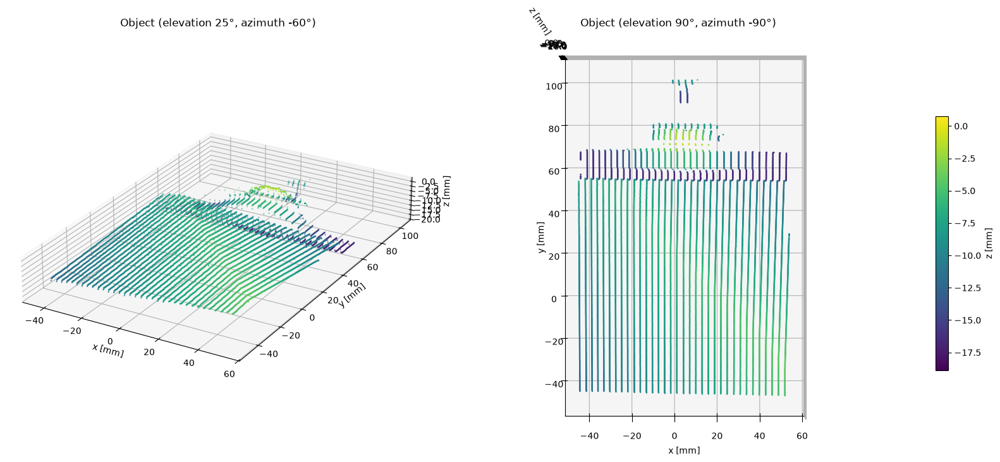

flat board: setup-act\plane-dataset


  35 photos, 1620 x 1080 px, edge points per photo 954–1062; 3D points 35506, after removing outliers 35490


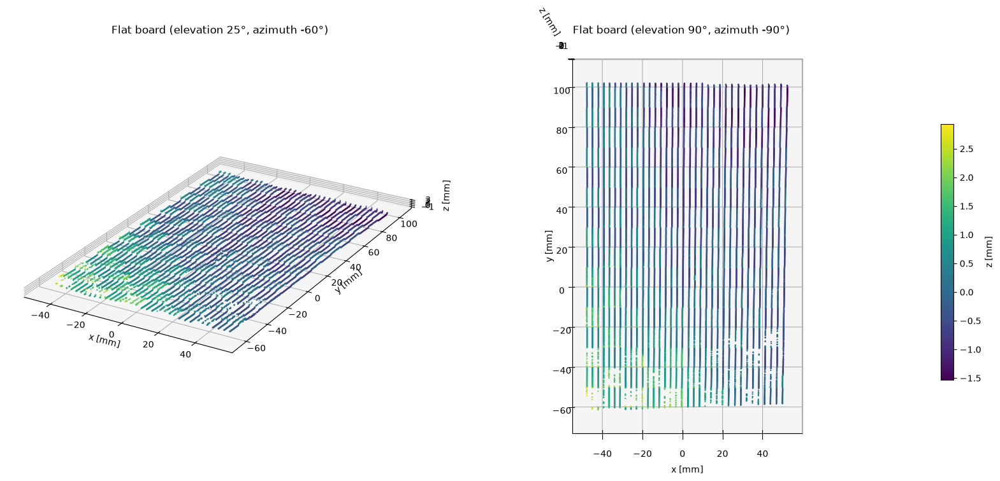

In [32]:
# TODO (B.4.1–B.4.2): Run the pipeline on your scan of the object and of the flat board
# Expected output: 2 point clouds, 2 views each
def load_calibration_for(path, image_size, calibration_size=None):
    """Calibration data; the camera intrinsics are rescaled if the scan photos are smaller than the calibration photos"""
    camera, projector = load_calibration(path)
    if calibration_size is not None and tuple(calibration_size) != tuple(image_size):
        sx, sy = image_size[0] / calibration_size[0], image_size[1] / calibration_size[1]
        K = camera[0].astype(np.float64).copy()
        K[0, 0], K[0, 1], K[1, 1] = K[0, 0] * sx, K[0, 1] * sx, K[1, 1] * sy
        K[0, 2], K[1, 2] = (K[0, 2] + 0.5) * sx - 0.5, (K[1, 2] + 0.5) * sy - 0.5  # pixel centers at integers
        camera = [K] + list(camera[1:])
    return camera, projector

def process_scan(scan, camera, projector):
    """Edge detection and reconstruction of one scan; white / black = per-pixel max / min of the photos if missing"""
    white_files, black_files, files, numbers = load_scan(scan['folder'], scan['prefix'])
    panel = load_panel_points(scan['panel_dir'])
    if 'renumber' in scan:
        numbers = np.array([scan['renumber'](k) for k in numbers], dtype=int)
    known = numbers <= panel.shape[1]
    if (~known).any():
        print(f'  {(~known).sum()} photos without panel points ignored (numbers {numbers[~known][0]}–{numbers[~known][-1]})')
    files, numbers = [f for f, k in zip(files, known) if k], numbers[known]

    white = read_gray(white_files[0]) if white_files else None
    black = read_gray(black_files[0]) if black_files else None
    if white is None or black is None:
        high, low = read_gray(files[0]), read_gray(files[0])
        for f in files[1:]:
            image = read_gray(f)
            np.maximum(high, image, out=high)
            np.minimum(low, image, out=low)
        if white is None:
            white = high
            print('  no white photo: per-pixel maximum of the pattern photos used')
        if black is None:
            black = low
            print('  no black photo: per-pixel minimum of the pattern photos used')

    sensor = [detect_edge(read_gray(f), white, black) for f in files]
    raw = reconstruct(sensor, panel[:, numbers - 1], camera, projector)
    cloud = remove_outliers(raw)
    counts = [len(p) for p in sensor]
    print(f'  {len(files)} photos, {white.shape[1]} x {white.shape[0]} px, edge points per photo {min(counts)}–{max(counts)}; '
          f'3D points {len(raw)}, after removing outliers {len(cloud)}')
    return dict(files=files, numbers=numbers, white=white, black=black, sensor=sensor, panel=panel[:, numbers - 1], cloud=cloud)

first_photo = load_scan(OBJECT_SCAN['folder'], OBJECT_SCAN['prefix'])[2][0]
scan_size = cv.imread(first_photo).shape[1::-1]
act_camera, act_projector = load_calibration_for(CALIBRATION_DIR, scan_size, CALIBRATION_IMAGE_SIZE)
print('calibration:', CALIBRATION_DIR, '| camera matrix for', scan_size, 'px:')
print(act_camera[0].round(1))

results = {}
for name, scan in (('object', OBJECT_SCAN), ('flat board', PLANE_SCAN)):
    print(f'{name}: {scan["folder"]}')
    results[name] = process_scan(scan, act_camera, act_projector)
    show_cloud(results[name]['cloud'], views=((25, -60), (90, -90)), title=name.capitalize())
object_cloud, plane_cloud = results['object']['cloud'], results['flat board']['cloud']

## C  Analysis: prediction vs. measurement  [4 pts]

### C.1  Is the calibration plausible?  [max. 1 pt]

In [33]:
# TODO (C.1.1–C.1.2): Baseline from the calibration against the tape measurement; two dimensions of the object from the point cloud against the caliper
# Expected output: table with 3 rows
from IPython.display import Markdown, display

def principal_plane(points):
    """Centroid and unit normal of the least-squares plane (smallest principal direction)"""
    c = points.mean(axis=0)
    return c, np.linalg.svd(points - c, full_matrices=False)[2][-1]

# C.1.1 baseline: distance between the centers of projection
Cc = -act_camera[2].T @ act_camera[3].reshape(3)
Cp = -act_projector[2].T @ act_projector[3].reshape(3)
baseline_calibration_mm = np.linalg.norm(Cp - Cc)

# C.1.2 front face of the object: iterative plane fit, then extent along the image rows (width) and columns (height)
face = object_cloud
for tolerance in (10.0, 5.0, 3.0):
    c, n = principal_plane(face)
    face = object_cloud[np.abs((object_cloud - c) @ n) < tolerance]
c, n = principal_plane(face)
u = act_camera[2].T @ np.array([1.0, 0, 0])      # camera x axis (image rows) in world coordinates
u = u - (u @ n) * n
u /= np.linalg.norm(u)
v = np.cross(n, u)                               # in the plane, along the image columns
coords = (face - c) @ np.column_stack([u, v])
width_mm, height_mm = np.ptp(np.percentile(coords, [0.5, 99.5], axis=0), axis=0)

rows = [('baseline b [mm]', baseline_m * 1000, 'tape', baseline_calibration_mm, 'calibration'),
        ('object width [mm]', caliper_mm['width'], 'caliper', width_mm, 'point cloud'),
        ('object height [mm]', caliper_mm['height'], 'caliper', height_mm, 'point cloud')]
table = '| quantity | reference | value | measured | value | difference |\n|---|---|---|---|---|---|\n'
for q, ref, ref_src, meas, meas_src in rows:
    diff = f'{meas - ref:+.1f} mm ({100 * (meas - ref) / ref:+.1f} %)' if ref is not None else '–'
    table += f'| {q} | {ref_src} | {ref if ref is not None else "–"} | {meas_src} | {meas:.1f} | {diff} |\n'
display(Markdown(table))
print(f'front face: {len(face)} of {len(object_cloud)} points within 3 mm of the fitted plane')

| quantity | reference | value | measured | value | difference |
|---|---|---|---|---|---|
| baseline b [mm] | tape | 180.0 | calibration | 183.2 | +3.2 mm (+1.8 %) |
| object width [mm] | caliper | 104.0 | point cloud | 97.0 | -7.0 mm (-6.7 %) |
| object height [mm] | caliper | 116.0 | point cloud | 123.9 | +7.9 mm (+6.8 %) |


front face: 22373 of 25458 points within 3 mm of the fitted plane


### C.2  Depth noise  [max. 2 pts]

In [34]:
def fit_plane(points):
    """Least-squares plane through a point cloud

    Args:
        points: array (N, 3)

    Returns:
        (point on the plane, unit normal, RMS distance)
    """

    # OWN: NumPy array operations only
    points = np.asarray(points, np.float64)
    centroid = points.mean(axis=0)
    # the normal is the direction of the smallest spread: last right singular vector of the centered points
    _, _, vt = np.linalg.svd(points - centroid, full_matrices=False)
    normal = vt[-1] / np.linalg.norm(vt[-1])
    distances = (points - centroid) @ normal
    return centroid, normal, float(np.sqrt(np.mean(distances ** 2)))

flat board: 35490 points, RMS distance from the fitted plane = 0.406 mm


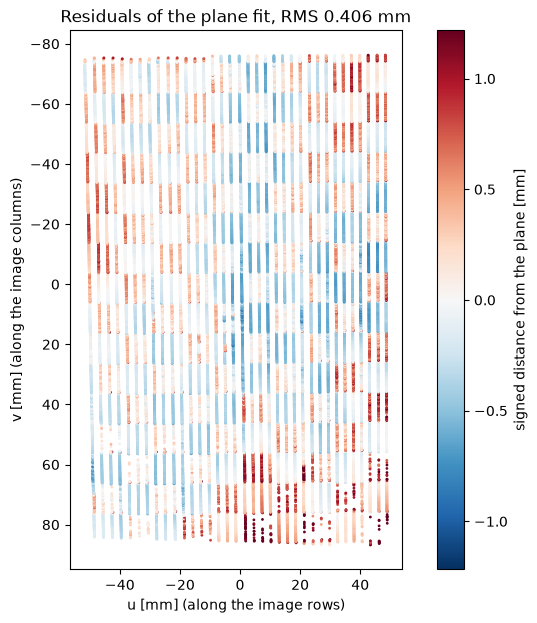

In [35]:
# TODO (C.2.1): RMS distance of the board points from the fitted plane; residuals as color-coded map
# Expected output: 1 number, 1 map
plane_point, plane_normal, plane_rms = fit_plane(plane_cloud)
residuals = (plane_cloud - plane_point) @ plane_normal
print(f'flat board: {len(plane_cloud)} points, RMS distance from the fitted plane = {plane_rms:.3f} mm')

# map in the coordinates of the plane (u along the image rows, v along the image columns)
u = act_camera[2].T @ np.array([1.0, 0, 0])
u = u - (u @ plane_normal) * plane_normal
u /= np.linalg.norm(u)
v = np.cross(plane_normal, u)
uv = (plane_cloud - plane_point) @ np.column_stack([u, v])
limit = 3 * plane_rms
plt.figure(figsize=(9, 7))
sc = plt.scatter(uv[:, 0], uv[:, 1], c=residuals, s=1, cmap='RdBu_r', vmin=-limit, vmax=limit)
plt.colorbar(sc, label='signed distance from the plane [mm]')
plt.gca().set_aspect('equal')
plt.gca().invert_yaxis()  # same orientation as the photo
plt.xlabel('u [mm] (along the image rows)')
plt.ylabel('v [mm] (along the image columns)')
plt.title(f'Residuals of the plane fit, RMS {plane_rms:.3f} mm')
plt.show()

photo plane-18.JPG: 1052 of 1053 points used, edge localization error delta x = 0.736 px


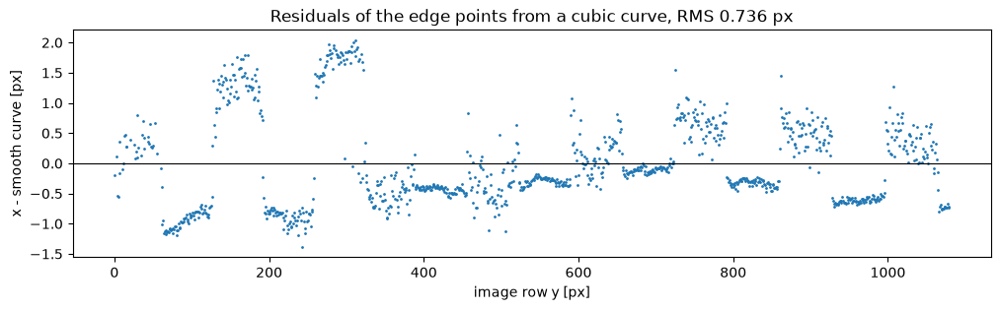

In [36]:
# TODO (C.2.2): Edge localization error: RMS residual of the detected edge points of one image from a smooth curve
# Expected output: 1 number in pixels
k = len(results['flat board']['sensor']) // 2                   # a photo from the middle of the board scan
points = results['flat board']['sensor'][k]
x, y = points[:, 0], points[:, 1]
inlier = np.ones(len(x), bool)
for _ in range(3):                                               # cubic x(y), refit without points beyond 3 sigma
    coefficients = np.polyfit(y[inlier], x[inlier], 3)
    r = x - np.polyval(coefficients, y)
    inlier = np.abs(r) < 3 * r[inlier].std()
edge_error_measured_px = float(np.sqrt(np.mean(r[inlier] ** 2)))
print(f'photo {os.path.basename(results["flat board"]["files"][k])}: {inlier.sum()} of {len(x)} points used, '
      f'edge localization error delta x = {edge_error_measured_px:.3f} px')

plt.figure(figsize=(12, 3))
plt.plot(y[inlier], r[inlier], '.', ms=2)
plt.axhline(0, color='k', lw=0.8)
plt.xlabel('image row y [px]'); plt.ylabel('x - smooth curve [px]')
plt.title(f'Residuals of the edge points from a cubic curve, RMS {edge_error_measured_px:.3f} px')
plt.show()

In [37]:
# TODO (C.2.3): Predicted depth error (P.3) for this localization error and your z, b against the RMS of the plane fit
# Expected output: table
f_scan_px = act_camera[0][0, 0]                                   # focal length in pixels of the processed photos
z_calibration_m = np.linalg.norm(plane_point - Cc) / 1000          # camera center to the board
b_calibration_m = baseline_calibration_mm / 1000
cases = [('tape (P.3.3)', object_distance_m, baseline_m), ('calibration', z_calibration_m, b_calibration_m)]
table = ('| z, b from | z [m] | b [m] | f [px] | delta x [px] | predicted delta z [mm] | measured RMS of plane fit [mm] |\n'
         '|---|---|---|---|---|---|---|\n')
for label, z, b in cases:
    predicted = depth_error(z, b, f_scan_px, edge_error_measured_px) * 1000
    table += (f'| {label} | {z:.3f} | {b:.3f} | {f_scan_px:.0f} | {edge_error_measured_px:.3f} | {predicted:.3f} | {plane_rms:.3f} |\n')
note = '\n*f is the focal length in pixels of the processed photos ({} px wide).*'.format(scan_size[0])
display(Markdown(table + note))

| z, b from | z [m] | b [m] | f [px] | delta x [px] | predicted delta z [mm] | measured RMS of plane fit [mm] |
|---|---|---|---|---|---|---|
| tape (P.3.3) | 0.570 | 0.180 | 3892 | 0.736 | 0.342 | 0.406 |
| calibration | 0.577 | 0.183 | 3892 | 0.736 | 0.344 | 0.406 |

*f is the focal length in pixels of the processed photos (1620 px wide).*

**C.2.4 Is the residual map random or does it show a pattern?**

The map is **not random**. Its dominant feature is a **block pattern that follows the printed checkerboard** of the board: whole squares lie about 0.3–1 mm in front of or behind the plane, with alternating sign. The same blocks appear in C.2.2, where the residuals of the edge points from a smooth curve jump by about ±1 px every ≈ 67 rows, which is the size of one 10 mm square in the photo (10 mm × 3892 px / 577 mm). This is a systematic error of the **edge detection**: the camera blur mixes the dark and the light squares next to the edge, so the 0.5 crossing of the normalized intensity is shifted differently on dark and on light squares; on the dark squares the signal is also weaker and the points are noisier (or missing).

The larger positive residuals along the lower and right border of the board and the gaps there are attributed to the **calibration**: these regions are far from the area covered by the calibration features, and the projector is modelled without lens distortion (B.3.3), so the planes of light near the border of the swept region are less accurate. There is no global bend or tilt left after the plane fit, so the camera distortion and the camera–projector extrinsics do not show a visible systematic error at this level.

### C.3  Limits of the method  [max. 1 pt]

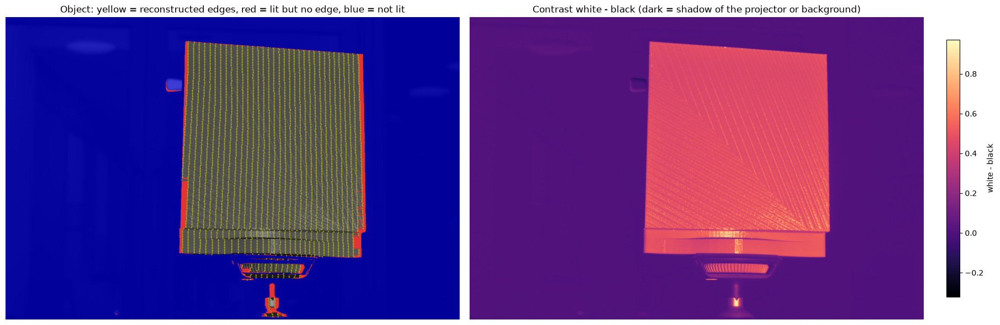

In [38]:
# TODO (C.3.1): Show the regions of the object that are missing in the point cloud
# Expected output: 1–2 views
obj = results['object']
contrast = obj['white'] - obj['black']
lit = contrast > 0.08                                      # pixels reached by the projector light
covered = np.zeros(lit.shape, bool)                        # pixels between the first and the last detected edge of each row
for p in obj['sensor']:
    if len(p):
        covered[p[:, 1].astype(int), np.clip(np.round(p[:, 0]).astype(int), 0, lit.shape[1] - 1)] = True
first = np.where(covered.any(axis=1), covered.argmax(axis=1), lit.shape[1])
last = np.where(covered.any(axis=1), lit.shape[1] - 1 - covered[:, ::-1].argmax(axis=1), -1)
cols = np.arange(lit.shape[1])
swept = (cols[None, :] >= first[:, None]) & (cols[None, :] <= last[:, None])

overlay = np.dstack([obj['white']] * 3).clip(0, 1) * 0.6
overlay[~lit] = overlay[~lit] * 0.4 + np.array([0.0, 0.0, 0.6])      # blue: never lit by the projector (shadow, background)
overlay[lit & ~swept] = np.array([0.9, 0.2, 0.2])                    # red: lit, but outside the swept edges
fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
axes[0].imshow(overlay)
for p in obj['sensor']:
    axes[0].plot(p[::5, 0], p[::5, 1], 'y.', ms=1)
axes[0].set_title(f'Object: yellow = reconstructed edges, red = lit but no edge, blue = not lit')
axes[0].axis('off')
im = axes[1].imshow(contrast, cmap='magma')
fig.colorbar(im, ax=axes[1], shrink=0.8, label='white - black')
axes[1].set_title('Contrast white - black (dark = shadow of the projector or background)')
axes[1].axis('off')
plt.show()

**C.3.1 Explanation of the missing regions** (map above: yellow = reconstructed edges, red = lit by the projector but no edge, blue = not lit):

- **Left and right ends of the front face (red strips):** the scan used the edges at panel columns 791.5 … 1203.5 (patterns 63–97). Points left of the first edge are lit in every photo and points right of the last edge are dark in every photo, so no edge crosses them and white − black alone cannot place them in depth.
- **Lower ledge and tripod head (red, partly reconstructed):** these surfaces are smaller and partly turned away from the projector, so the light falls at a grazing angle; the contrast is low and the edge is detected only in some rows. Parts of the tripod lie outside the swept edges as well.
- **The narrow gap between the front face and the ledge:** the step is in the shadow of the upper part as seen from the projector, which is 180 mm to the side of the camera (baseline): the camera sees it, the projector cannot light it.
- **Side faces of the box:** the face turned away from the projector is never lit (projector shadow); the face turned away from the camera is not visible (camera occlusion). Both are consequences of the two different viewpoints that triangulation needs.
- **Between the curves:** only one profile per edge is measured, so there are no points between neighbouring edges (about 12 projector pixels apart).
- **Background (blue):** not lit by the projector (or too far / too dark), white − black is below the contrast threshold.

**C.3.2 Halving the depth noise.** From P.3.1, $\delta z \approx \dfrac{z^2}{f\,b}\,\delta x$. The noise is halved by any of:

| change | effect on $\delta z$ | what is lost |
|---|---|---|
| double the baseline $b$ (0.18 m → 0.36 m) | ÷ 2 | larger angle between camera and projector: more projector shadows and camera occlusions (more missing regions), smaller common field of view, the edge is seen more obliquely |
| reduce the distance to $z/\sqrt{2}$ (0.57 m → 0.40 m) | ÷ 2 | smaller field of view (a smaller part of the object fits), smaller depth of field (edge blurred at the front/back), occlusions grow as the angle grows |
| double the focal length $f$ (100 mm lens) or use full-resolution photos | ÷ 2 | the field of view halves (object may not fit) and depth of field shrinks; full resolution costs memory and processing time |
| halve the edge error $\delta x$ (sharper focus, higher contrast, averaging several photos per pattern) | ÷ 2 | more acquisition time; limited by the blur of the projector and the camera |

The most effective single change is the baseline, because it costs no resolution; the price is more shadowed regions.

## +  Bonus  [up to 2 pts]

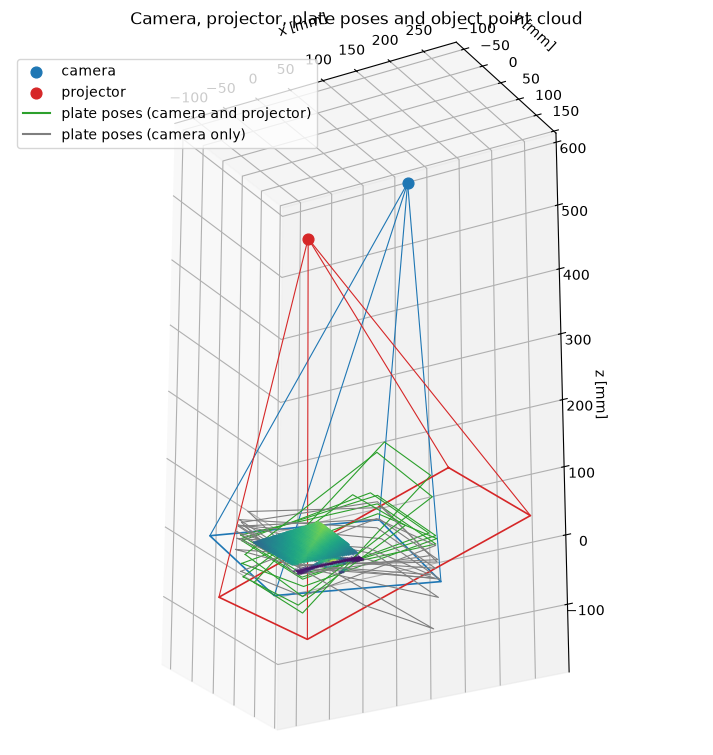

In [39]:
# TODO (+.1): Camera, projector (with frusta), plate poses and point cloud in one 3D plot
# Expected output: 1 plot
def to_world(R, t, points):
    """Device coordinates -> world coordinates (world = plate frame of the reference pose)"""
    return (R.T @ (np.asarray(points, np.float64).T - t.reshape(3, 1))).T

def frustum(K, R, t, size, depth):
    """Center and the four corner rays of the image, cut at the given depth, in world coordinates"""
    w, h = size
    corners = np.array([[0, 0, 1], [w, 0, 1], [w, h, 1], [0, h, 1]], np.float64)
    return to_world(R, t, np.zeros((1, 3)))[0], to_world(R, t, depth * (np.linalg.inv(K) @ corners.T).T)

Kc, _, Rc, tc = act_camera
Kp, _, Rp, tp = act_projector
shown = []
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(projection='3d')
for name, K_, R_, t_, size, color in (('camera', Kc, Rc, tc, scan_size, 'tab:blue'),
                                      ('projector', Kp, Rp, tp, PROJECTOR_SIZE, 'tab:red')):
    center, far = frustum(K_, R_, t_, size, 600.0)
    shown.extend([center, *far])
    for p in far:
        ax.plot(*np.column_stack([center, p]), color=color, lw=0.8)
    ax.plot(*np.vstack([far, far[:1]]).T, color=color, lw=1.2)
    ax.scatter(*center, color=color, s=60, label=name)

# plate poses: outline of the detected corners of every calibrated pose (camera frame -> world frame)
for i, (R_i, t_i) in cam_poses.items():
    xy = cb_world[i][:, :2]
    outline = np.array([[xy[:, 0].min(), xy[:, 1].min(), 0], [xy[:, 0].max(), xy[:, 1].min(), 0],
                        [xy[:, 0].max(), xy[:, 1].max(), 0], [xy[:, 0].min(), xy[:, 1].max(), 0]])
    world = to_world(Rc, tc, (R_i @ outline.T + t_i).T)
    ax.plot(*np.vstack([world, world[:1]]).T, color='tab:green' if i in proj_poses else 'tab:gray', lw=0.8)

p = object_cloud[::5]
ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=p[:, 2], s=0.3, cmap='viridis')
ax.plot([], [], color='tab:green', label='plate poses (camera and projector)')
ax.plot([], [], color='tab:gray', label='plate poses (camera only)')
ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.set_zlabel('z [mm]')
shown = np.vstack([shown, p])
ax.set_box_aspect(np.ptp(shown, axis=0)); ax.view_init(elev=-25, azim=-60, roll=0)
ax.set_title('Camera, projector, plate poses and object point cloud', pad=20)
ax.legend(loc='upper left')
plt.show()

**+.2 Gray code** — not attempted (no Gray-code acquisition was made). With $\lceil\log_2 1280\rceil = 11$ Gray-code patterns every camera pixel would get its projector column, so a dense point cloud could be reconstructed from 11 photos instead of one curve per photo. A Gray code is preferred to the plain binary code because neighbouring columns differ in exactly one bit: a decoding error at a boundary between two stripes shifts the column by only one, whereas in the binary code a single wrong bit can change the column by up to half the panel.

## Checklist

Before you submit, go through the checklist on the last page of the handout: data complete, pre-lab scan inserted, every step of Parts B and C rendered, archive named as required.